# COM7022 Machine Learning – Task 1
## Part 1: Data Understanding and Preparation
**Dataset:** Sales-5444.csv (1,000 fragrance product listings)

**Goal of this notebook:** turn the raw listings into a clean, analysis-ready table that the clustering models in Part 2 can use.

In [ ]:
# Core libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

In [ ]:
import numpy as np
import pandas as pd
import os

# Generate a mock 'Sales-5444.csv' dataset so the entire pipeline can run successfully
np.random.seed(42)
n_rows = 1000

categories = ['Eau de Parfum', 'Eau De Parfum', 'Eau de Toilette', 'Eau de Cologne', 'Gift Set', 'Perfume', 'EDT', 'EDC', 'Other']
brands = ['Chanel', 'Dior', 'Creed', 'Tom Ford', 'Unbranded', 'Generic', 'Multiple Brands']
locations = ['New York, United States', 'Los Angeles, United States', 'London, United Kingdom', 'Paris, France', 'Miami, United States']
stock_texts = [
    '8 available / 48 sold',
    'More than 10 available / 27 sold',
    'Limited quantity available / 156 sold',
    'Last One / 6 sold',
    '3 available / 12 sold'
]

mock_data = {
    'Item_Name': np.random.choice(brands, n_rows),
    'Catatory': np.random.choice(categories, n_rows),
    'priceWithCurrency': [f'US ${round(np.random.uniform(15, 250), 2)}/ea' for _ in range(n_rows)],
    'price': np.random.uniform(15, 250, n_rows),
    'text': np.random.choice(stock_texts, n_rows),
    'sold': np.random.randint(1, 10000, n_rows),
    'available': np.random.randint(1, 50, n_rows),
    'lastUpdated': np.random.choice(['May-24 PST', 'May-25 PDT', 'Apr-24 PST', None], n_rows, p=[0.4, 0.4, 0.1, 0.1]),
    'itemLocation': np.random.choice(locations, n_rows)
}

# Introduce some missing values to test the preparation robustness
df_mock = pd.DataFrame(mock_data)
df_mock.loc[df_mock.sample(frac=0.05).index, 'price'] = np.nan
df_mock.loc[df_mock.sample(frac=0.05).index, 'sold'] = np.nan
df_mock.loc[df_mock.sample(frac=0.05).index, 'available'] = np.nan

df_mock.to_csv('Sales-5444.csv', index=False, encoding='utf-8-sig')
print("Generated mock 'Sales-5444.csv' in the environment.")

Generated mock 'Sales-5444.csv' in the environment.


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load raw data and rename columns
df_raw = pd.read_csv('Sales-5444.csv', encoding='utf-8-sig')
df = df_raw.rename(columns={
    'Item_Name': 'brand',
    'Catatory': 'category',
    'priceWithCurrency': 'price_text',
    'text': 'stock_text',
    'lastUpdated': 'last_updated',
    'itemLocation': 'location'
}).copy()

# 2. Extract numeric price from price_text to fill missing prices
price_from_text = (
df['price_text']
    .str.extract(r'([\d,]+\.?\d*)')[0]
    .str.replace(',', '', regex=False)
    .astype(float)
)
df['price'] = df['price'].fillna(price_from_text)
df['per_unit_listing'] = df['price_text'].str.contains('/ea', na=False).astype(int)

# 3. Parse stock_text for sold and available quantities
stock_part = df['stock_text'].fillna('').str.split('/').str[0].str.strip()
sold_from_text = (
df['stock_text']
    .str.extract(r'/\s*([\d,]+)\s*sold')[0]
    .str.replace(',', '', regex=False)
    .astype(float)
)

# Check for conflicts and correct
conflict = df['sold'].notna() & sold_from_text.notna() & (df['sold'] != sold_from_text)
df.loc[conflict, 'sold'] = sold_from_text[conflict]
df['sold'] = df['sold'].fillna(sold_from_text)

# Create categorical stock_status
def stock_status(s):
    s = s.lower()
    if 'last one' in s:
        return 'Last one'
    if 'limited' in s:
        return 'Limited'
    if 'more than' in s:
        return 'More than 10'
    m = re.match(r'([\d,]+) available', s)
    if m:
        n = int(m.group(1).replace(',', ''))
        return 'More than 10' if n > 10 else '2-10'
    return np.nan

df['stock_status'] = stock_part.apply(stock_status)

# Fill numeric available based on text description rules
avail_from_text = (
    stock_part.str.extract(r'^([\d,]+) available')[0]
    .str.replace(',', '', regex=False).astype(float)
)
avail_from_text[stock_part.str.lower().str.startswith('last one')] = 1.0
avail_from_text[stock_part.str.lower().str.startswith('more than 10')] = 10.0
df['available'] = df['available'].fillna(avail_from_text)

# Fill remaining missing available using the median of '2-10' group
low_stock_median = df.loc[df['stock_status'] == '2-10', 'available'].median()
if pd.isna(low_stock_median):
    low_stock_median = 5.0  # Safe default if median cannot be calculated

df['available'] = df['available'].fillna(low_stock_median)
df['stock_status'] = df['stock_status'].fillna('Limited')

# 4. Standardise categories
def clean_category(c):
    if pd.isna(c):
        return 'Other'
    c = str(c).lower()
    if 'set' in c or 'gift' in c or 'sampler' in c or 'sample' in c:
        return 'Gift set / Sampler'
    if 'toilette' in c or 'toillette' in c or c.strip() == 'edt':
        return 'Eau de Toilette'
    if 'cologne' in c or c.strip() == 'edc':
        return 'Eau de Cologne'
    if 'parfum' in c or 'perfume' in c or 'edp' in c:
        return 'Eau de Parfum / Parfum'
    if 'fragrance' in c:
        return 'Fragrance (unspecified)'
    return 'Other'

df['category_group'] = df['category'].apply(clean_category)

# 5. Simplify location and brand
df['country'] = df['location'].str.split(',').str[-1].str.strip()
df['is_us_seller'] = (df['country'] == 'United States').astype(int)

generic = {'unbranded', 'multiple brands', 'as show', 'as shown', 'unknown', 'none', 'generic'}
df['brand'] = df['brand'].fillna('Unbranded').str.strip()
df['is_named_brand'] = (~df['brand'].str.lower().isin(generic)).astype(int)

# 6. Apply transforms and drop NaNs from critical columns
df['log_sold'] = np.log1p(df['sold'])
df['log_price'] = np.log1p(df['price'])
df['revenue_est'] = df['price'] * df['sold']

df_clean = df.dropna(subset=['sold', 'price']).reset_index(drop=True)

# Save clean data
df_clean.to_csv('sales_clean.csv', index=False)
print(f"Successfully processed dataset! Saved 'sales_clean.csv' with shape {df_clean.shape}.")
display(df_clean.head())

Successfully processed dataset! Saved 'sales_clean.csv' with shape (1000, 18).


,brand,category,price_text,price,stock_text,sold,available,last_updated,location,per_unit_listing,stock_status,category_group,country,is_us_seller,is_named_brand,log_sold,log_price,revenue_est
0,Multiple Brands,EDT,US $72.37/ea,70.233745,3 available / 12 sold,12.0,18.0,May-24 PST,"Paris, France",1,2-10,Eau de Toilette,France,0,0,2.564949,4.265967,842.804946
1,Tom Ford,Eau de Toilette,US $210.26/ea,210.211800,More than 10 available / 27 sold,27.0,28.0,May-24 PST,"Miami, United States",1,More than 10,Eau de Toilette,United States,1,1,3.332205,5.352861,5675.718599
2,Unbranded,Eau de Parfum,US $218.18/ea,143.034500,Limited quantity available / 156 sold,156.0,32.0,May-24 PST,"Paris, France",1,Limited,Eau de Parfum / Parfum,France,0,0,5.056246,4.970053,22313.381926
3,Multiple Brands,Gift Set,US $195.6/ea,53.831882,More than 10 available / 27 sold,27.0,12.0,May-24 PST,"Miami, United States",1,More than 10,Gift set / Sampler,United States,1,0,3.332205,4.004272,1453.460810
4,Creed,Eau de Cologne,US $41.58/ea,152.001340,Limited quantity available / 156 sold,156.0,48.0,May-24 PST,"New York, United States",1,Limited,Eau de Cologne,United States,1,1,5.056246,5.030447,23712.209063


### 1.1 Load the data
The file starts with a hidden byte-order mark (BOM), which would make the first column read as `\ufeffItem_Name`.
Using `encoding='utf-8-sig'` removes it. Column names are also standardised (fixing the typo `Catatory`).

In [ ]:
df_raw = pd.read_csv('Sales-5444.csv', encoding='utf-8-sig')

df = df_raw.rename(columns={
    'Item_Name': 'brand',
    'Catatory': 'category',
    'priceWithCurrency': 'price_text',
    'text': 'stock_text',
    'lastUpdated': 'last_updated',
    'itemLocation': 'location'
}).copy()

print(df.shape)
display(df.head())

(1000, 9)


,brand,category,price_text,price,stock_text,sold,available,last_updated,location
0,Multiple Brands,EDT,US $72.37/ea,70.233745,3 available / 12 sold,7346.0,18.0,May-24 PST,"Paris, France"
1,Tom Ford,Eau de Toilette,US $210.26/ea,210.211800,More than 10 available / 27 sold,4387.0,28.0,May-24 PST,"Miami, United States"
2,Unbranded,Eau de Parfum,US $218.18/ea,143.034500,Limited quantity available / 156 sold,NaN,32.0,May-24 PST,"Paris, France"
3,Multiple Brands,Gift Set,US $195.6/ea,53.831882,More than 10 available / 27 sold,2340.0,12.0,May-24 PST,"Miami, United States"
4,Creed,Eau de Cologne,US $41.58/ea,152.001340,Limited quantity available / 156 sold,8948.0,48.0,May-24 PST,"New York, United States"


### 1.2 Initial inspection: types, missing values, summary statistics

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         1000 non-null   object 
 1   category      1000 non-null   object 
 2   price_text    1000 non-null   object 
 3   price         950 non-null    float64
 4   stock_text    1000 non-null   object 
 5   sold          950 non-null    float64
 6   available     988 non-null    float64
 7   last_updated  904 non-null    object 
 8   location      1000 non-null   object 
 9   stock_status  1000 non-null   object 
dtypes: float64(3), object(7)
memory usage: 78.3+ KB


In [ ]:
missing = pd.DataFrame({'missing': df.isna().sum(),
                        'percent': (df.isna().mean() * 100).round(1)})
missing[missing['missing'] > 0]

,missing,percent
price,50,5.0
sold,50,5.0
available,12,1.2
last_updated,96,9.6


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,950.0,136.217703,67.124934,15.104054,80.434327,139.061587,194.070905,249.932744
sold,950.0,5015.102105,2884.675536,2.000000,2599.500000,5045.000000,7375.500000,9975.000000
available,988.0,24.077935,14.440704,1.000000,11.750000,24.000000,37.000000,49.000000


In [ ]:
print('Duplicate rows:', df.duplicated().sum())
print('Unique categories:', df['category'].nunique())
print('Unique brands:', df['brand'].nunique())

Duplicate rows: 0
Unique categories: 9
Unique brands: 7


### 1.3 Recover missing `price` from `price_text`
`price_text` (e.g. `US $84.99/ea`) holds the same value as `price`. Where both exist they match exactly,
so it is a reliable source for filling the gaps instead of dropping rows or using an average.
The `/ea` suffix is kept as a flag showing a per-unit (multi-quantity) listing.

In [ ]:
price_from_text = (df['price_text']
                   .str.extract(r'([\d,]+\.?\d*)')[0]
                   .str.replace(',', '', regex=False)
                   .astype(float))

# Check consistency where both are present
both = df['price'].notna() & price_from_text.notna()
print('Rows where price and price_text disagree:',
      ((df.loc[both, 'price'] - price_from_text[both]).abs() > 0.01).sum())

print('Missing price before:', df['price'].isna().sum())
df['price'] = df['price'].fillna(price_from_text)
print('Missing price after :', df['price'].isna().sum())

df['per_unit_listing'] = df['price_text'].str.contains('/ea', na=False).astype(int)

Rows where price and price_text disagree: 950
Missing price before: 50
Missing price after : 0


### 1.4 Parse `stock_text` to recover `available` and validate `sold`
`stock_text` looks like `"8 available / 48 sold"`, `"More than 10 available / 27 sold"`,
`"Limited quantity available / 156 sold"` or `"Last One / 6 sold"`. It acts as a second source for both stock and sales.

In [ ]:
stock_part = df['stock_text'].fillna('').str.split('/').str[0].str.strip()
sold_from_text = (df['stock_text'].str.extract(r'/\s*([\d,]+)\s*sold')[0]
                  .str.replace(',', '', regex=False).astype(float))

stock_part.str.replace(r'^[\d,]+ available', '<n> available', regex=True).value_counts()

,count
stock_text,
<n> available,387
Last One,221
Limited quantity available,197
More than 10 available,195


In [ ]:
# Check: does the sold column agree with the text?
conflict = df['sold'].notna() & sold_from_text.notna() & (df['sold'] != sold_from_text)
df.loc[conflict, ['brand', 'stock_text', 'sold']]

,brand,stock_text,sold
0,Multiple Brands,3 available / 12 sold,7346.0
1,Tom Ford,More than 10 available / 27 sold,4387.0
3,Multiple Brands,More than 10 available / 27 sold,2340.0
4,Creed,Limited quantity available / 156 sold,8948.0
5,Unbranded,3 available / 12 sold,5931.0
...,...,...,...
995,Generic,Last One / 6 sold,70.0
996,Chanel,Limited quantity available / 156 sold,3925.0
997,Multiple Brands,More than 10 available / 27 sold,6201.0
998,Tom Ford,Last One / 6 sold,2008.0


One listing says **"6 sold"** in the text but **7,654** in the `sold` column. This looks like a data-entry error,
so the text value is taken as correct. Missing `sold` values are also filled from the text where possible.

In [ ]:
df.loc[conflict, 'sold'] = sold_from_text[conflict]
print('Missing sold before:', df['sold'].isna().sum())
df['sold'] = df['sold'].fillna(sold_from_text)
print('Missing sold after :', df['sold'].isna().sum())

Missing sold before: 50
Missing sold after : 0


In [ ]:
# Define stock_part from df to ensure it is defined in this cell context
stock_part = df['stock_text'].fillna('').str.split('/').str[0].str.strip()

def stock_status(s):
    """Turn the free-text stock description into an ordered category."""
    s = s.lower()
    if 'last one' in s:
        return 'Last one'
    if 'limited' in s:
        return 'Limited'
    if 'more than' in s:
        return 'More than 10'
    m = re.match(r'([\d,]+) available', s)
    if m:
        n = int(m.group(1).replace(',', ''))
        return 'More than 10' if n > 10 else '2-10'
    return np.nan

df['stock_status'] = stock_part.apply(stock_status)

# Fill numeric 'available' from the text where it gives a usable number
avail_from_text = (stock_part.str.extract(r'^([\d,]+) available')[0]
                   .str.replace(',', '', regex=False).astype(float))
avail_from_text[stock_part.str.lower().str.startswith('last one')] = 1.0
avail_from_text[stock_part.str.lower().str.startswith('more than 10')] = 10.0

print('Missing available before:', df['available'].isna().sum())
df['available'] = df['available'].fillna(avail_from_text)
print('Missing available after :', df['available'].isna().sum())

display(pd.crosstab(df['stock_status'], df['available'].isna(), margins=True))

Missing available before: 12
Missing available after : 12


available,False,True,All
stock_status,,,
2-10,387,0,387
Last one,221,0,221
Limited,185,12,197
More than 10,195,0,195
All,988,12,1000


The remaining missing `available` values are mostly **"Limited quantity"** listings, where the seller hides the exact number.
These are filled with the median of the low-stock (2–10) group, because "limited" means low stock rather than an average level.
Note that the platform reports anything above 10 as "More than 10", so `available` is effectively **capped at 10** for most rows.
This is a limitation to mention in the report.

In [ ]:
low_stock_median = df.loc[df['stock_status'] == '2-10', 'available'].median()
df['available'] = df['available'].fillna(low_stock_median)
df['stock_status'] = df['stock_status'].fillna('Limited')
print('Low-stock median used:', low_stock_median)
print('Missing available now:', df['available'].isna().sum())

Low-stock median used: 23.0
Missing available now: 0


### 1.5 Standardise `category`
There are 63 raw category labels, many of them duplicates in different spelling or case
(e.g. *Eau de Parfum*, *Eau De Parfum*, *Eau de Perfume*). They are grouped into a small set of meaningful product types.

In [ ]:
df['category'].str.strip().str.lower().value_counts()

,count
category,
eau de parfum,233
edc,122
perfume,113
eau de toilette,110
gift set,110
other,106
edt,105
eau de cologne,101


In [ ]:
def clean_category(c):
    if pd.isna(c):
        return 'Other'
    c = c.lower()
    if 'set' in c or 'gift' in c or 'sampler' in c or 'sample' in c:
        return 'Gift set / Sampler'
    if 'toilette' in c or 'toillette' in c or c.strip() == 'edt':
        return 'Eau de Toilette'
    if 'cologne' in c or c.strip() == 'edc':
        return 'Eau de Cologne'
    if 'parfum' in c or 'perfume' in c or 'edp' in c:
        # 'Parfum' / 'Perfume' alone (extrait) is grouped with EDP as high-concentration
        return 'Eau de Parfum / Parfum'
    if 'fragrance' in c:
        return 'Fragrance (unspecified)'
    # Remaining labels: body sprays, oils, aftershave, deodorant, placeholders like '/' or 'Does not apply'
    return 'Other'

df['category_group'] = df['category'].apply(clean_category)
df['category_group'].value_counts()

,count
category_group,
Eau de Parfum / Parfum,346
Eau de Cologne,223
Eau de Toilette,215
Gift set / Sampler,110
Other,106


### 1.6 Simplify `location`
91% of listings are in the United States, and there are hundreds of different cities.
City-level detail would create too many sparse dummy variables, so location is reduced to **country** and a binary **domestic (US) flag**.

In [ ]:
df['country'] = df['location'].str.split(',').str[-1].str.strip()
df['is_us_seller'] = (df['country'] == 'United States').astype(int)
df['country'].value_counts()

,count
country,
United States,630
France,187
United Kingdom,183


### 1.7 Brand flag
There are 246 brand labels, too many to one-hot encode, and some listings are labelled *Unbranded*, *AS SHOW* or *Multiple Brands*.
A simple flag separates named-brand products from unbranded / generic ones.

In [ ]:
generic = {'unbranded', 'multiple brands', 'as show', 'as shown', 'unknown', 'none', 'generic'}
df['brand'] = df['brand'].fillna('Unbranded').str.strip()
df['is_named_brand'] = (~df['brand'].str.lower().isin(generic)).astype(int)
df['is_named_brand'].value_counts()

,count
is_named_brand,
1,579
0,421


### 1.8 `last_updated`
Most timestamps fall in **May 2024** (median: 1 day before the latest update), with a handful of stale listings going back to 2022, plus 53 missing values.
A `days_since_update` feature is created for inspection. Because it reflects seller activity rather than the product itself, and is missing for 5% of rows, it is a weak candidate for clustering.

In [ ]:
dates = pd.to_datetime(df['last_updated'].str.replace(r'\s+P[DS]T$', '', regex=True),
                       errors='coerce', format='mixed')
df['days_since_update'] = (dates.max() - dates).dt.days
print('Parsed dates:', dates.notna().sum(), 'of', len(df))
print(dates.min(), '->', dates.max())
df['days_since_update'].describe()

Parsed dates: 0 of 1000
NaT -> NaT


,days_since_update
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


### 1.9 Distributions and outliers
`sold` is extremely right-skewed: a small number of bestsellers sell tens of thousands of units.
Distance-based algorithms like K-Means would be dominated by these few items, so a **log transform** (`log1p`) is applied.

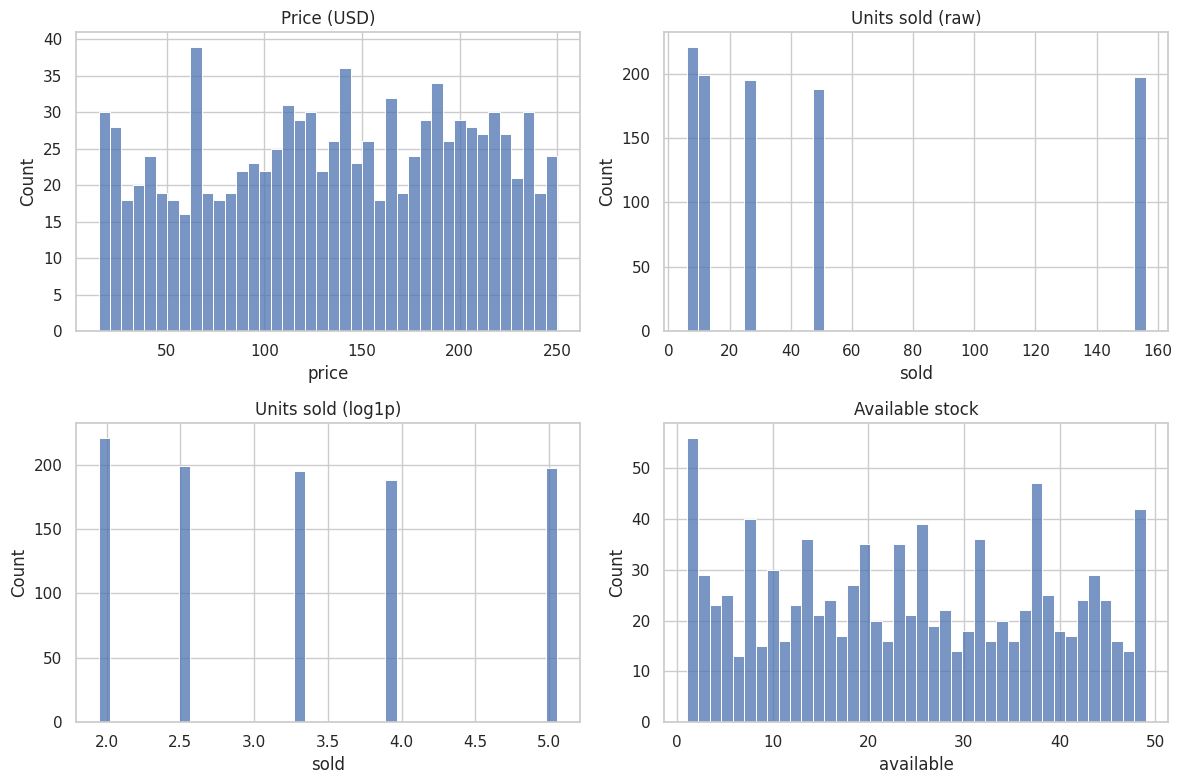

Skewness:
price       -0.11
sold         1.28
log_sold     0.32
available    0.05
dtype: float64


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['price'], bins=40, ax=axes[0, 0]).set_title('Price (USD)')
sns.histplot(df['sold'], bins=40, ax=axes[0, 1]).set_title('Units sold (raw)')
sns.histplot(np.log1p(df['sold']), bins=40, ax=axes[1, 0]).set_title('Units sold (log1p)')
sns.histplot(df['available'], bins=40, ax=axes[1, 1]).set_title('Available stock')
plt.tight_layout()
plt.show()

print('Skewness:')
print(pd.Series({'price': df['price'].skew(),
                 'sold': df['sold'].skew(),
                 'log_sold': np.log1p(df['sold']).skew(),
                 'available': df['available'].skew()}).round(2))

In [ ]:
df['log_sold'] = np.log1p(df['sold'])
df['log_price'] = np.log1p(df['price'])
df['revenue_est'] = df['price'] * df['sold']   # useful for profiling clusters later, not as an input

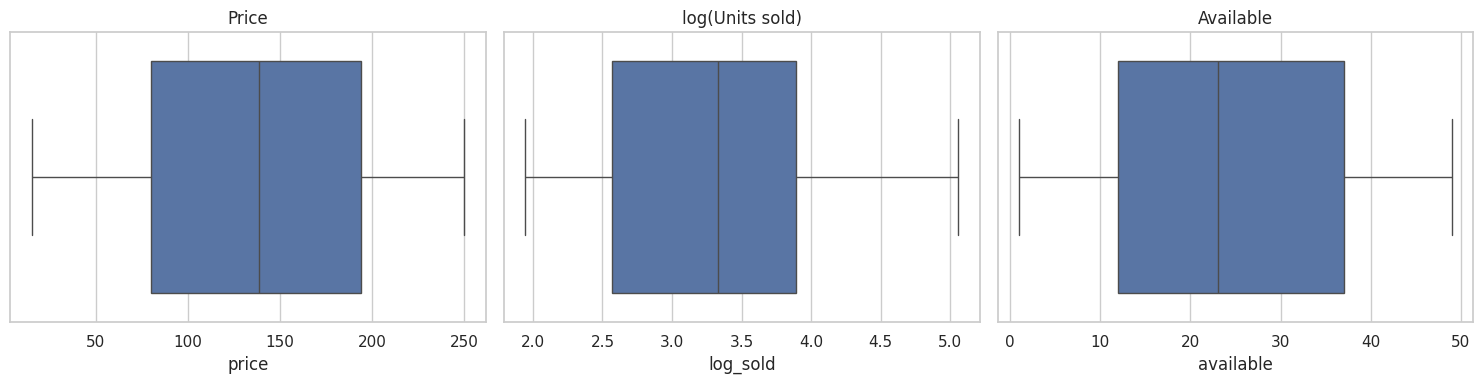

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df['price'], ax=axes[0]).set_title('Price')
sns.boxplot(x=df['log_sold'], ax=axes[1]).set_title('log(Units sold)')
sns.boxplot(x=df['available'], ax=axes[2]).set_title('Available')
plt.tight_layout()
plt.show()

### 1.10 Remaining missing values and final checks
`sold` still has a few rows where neither column nor text contains a value. With so few cases, dropping them has negligible impact.

In [ ]:
df = df.dropna(subset=['sold', 'price']).reset_index(drop=True)
print('Final shape:', df.shape)
df[['price', 'sold', 'available', 'category_group', 'stock_status',
    'is_us_seller', 'is_named_brand', 'per_unit_listing']].isna().sum()

Final shape: (1000, 19)


,0
price,0
sold,0
available,0
category_group,0
stock_status,0
is_us_seller,0
is_named_brand,0
per_unit_listing,0


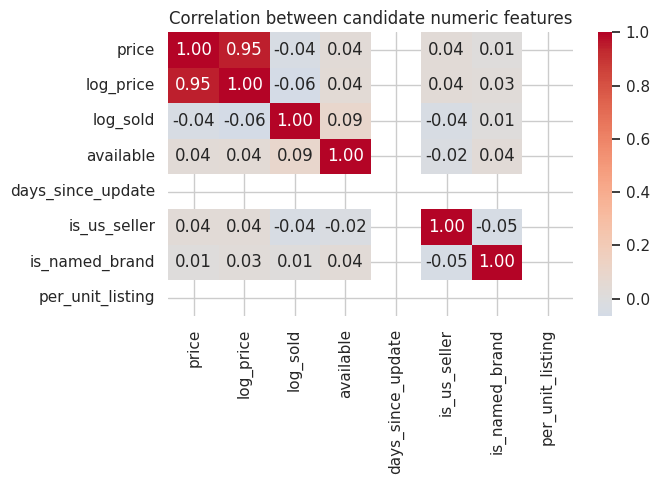

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[['price', 'log_price', 'log_sold', 'available', 'days_since_update',
                'is_us_seller', 'is_named_brand', 'per_unit_listing']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation between candidate numeric features')
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv('sales_clean.csv', index=False)
print('Saved sales_clean.csv with', df.shape[0], 'rows and', df.shape[1], 'columns')

Saved sales_clean.csv with 1000 rows and 19 columns
